In [1]:
!pip install -q ultralytics roboflow albumentations imagehash

import os, json, glob, random, shutil, hashlib, yaml
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CSS_BASE = '/kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data'
if not os.path.exists(CSS_BASE):
    hits = glob.glob('/kaggle/input/**/css-data', recursive=True)
    assert hits, "css-data not found — attach the snehilsanyal Kaggle dataset as an input"
    CSS_BASE = hits[0]
print("css-data:", CSS_BASE, os.listdir(CSS_BASE))

WORK = '/kaggle/working'
UNIFIED = f'{WORK}/ppe_unified'          
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
ROBOFLOW_API_KEY = user_secrets.get_secret("ROBOFLOW_API_KEY")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.0/285.0 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 58.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 110.0 MB/s eta 0:00:00
css-data: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data ['README.dataset.txt', 'README.roboflow.txt', 'valid', 'test', 'train']


In [2]:
from roboflow import Roboflow
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

# Dataset 1 — HardHat & SafetyVest (head / helmet / vest)
ds1 = rf.workspace("ppe-kit-detection").project("hardhat-safetyvest").version(1).download("yolov8", location=f"{WORK}/ds1_hardhat_vest")
BASE_DS1 = ds1.location

# Dataset 2 — PPE Combined Model (14 classes incl. NO- states)
ds2 = rf.workspace("roboflow-universe-projects").project("personal-protective-equipment-combined-model").version(1).download("yolov8", location=f"{WORK}/ds2_ppe_combined")
BASE_DS2 = ds2.location

# Dataset 3 — Workplace Safety (held out as EXTERNAL test set only)
ds3 = rf.workspace("siabar").project("ppe-dataset-for-workplace-safety").version(2).download("yolov8", location=f"{WORK}/ds3_workplace_safety")
BASE_DS3 = ds3.location

for b in [BASE_DS1, BASE_DS2, BASE_DS3]:
    with open(f"{b}/data.yaml") as f:
        print(b, "->", yaml.safe_load(f)['names'])

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/ds1_hardhat_vest in yolov8:: 100%|██████████| 44148/44148 [00:05<00:00, 7850.84it/s]


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/ds2_ppe_combined in yolov8:: 100%|██████████| 88016/88016 [00:17<00:00, 5119.44it/s] 


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/ds3_workplace_safety in yolov8:: 100%|██████████| 3238/3238 [00:00<00:00, 7327.21it/s]

/kaggle/working/ds1_hardhat_vest -> ['head', 'helmet', 'vest']
/kaggle/working/ds2_ppe_combined -> ['Fall-Detected', 'Gloves', 'Goggles', 'Hardhat', 'Ladder', 'Mask', 'NO-Gloves', 'NO-Goggles', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest']
/kaggle/working/ds3_workplace_safety -> ['Boots', 'Ear-protection', 'Glass', 'Glove', 'Helmet', 'Mask', 'Person', 'Vest']


In [3]:
CSS_CLASSES = ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest',
               'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']
NC = len(CSS_CLASSES)

def scan_split(base, split):
    """Read every YOLO label file in a split -> per-class counts, bbox areas, per-image class sets."""
    lbl_dir = f"{base}/{split}/labels"
    counts = Counter(); areas = defaultdict(list); img_classsets = []
    n_imgs = n_empty = 0
    for lf in glob.glob(f"{lbl_dir}/*.txt"):
        n_imgs += 1
        classes_here = set()
        with open(lf) as f:
            lines = [l.split() for l in f.read().strip().splitlines() if l.strip()]
        if not lines:
            n_empty += 1
        for parts in lines:
            cid = int(parts[0]); w, h = float(parts[3]), float(parts[4])
            counts[cid] += 1; areas[cid].append(w * h); classes_here.add(cid)
        img_classsets.append(classes_here)
    return counts, areas, img_classsets, n_imgs, n_empty

stats = {}
for split in ['train', 'valid', 'test']:
    counts, areas, sets_, n_imgs, n_empty = scan_split(CSS_BASE, split)
    stats[split] = dict(counts=counts, areas=areas, sets=sets_, n_imgs=n_imgs, n_empty=n_empty)
    print(f"{split:6s}: {n_imgs} label files, {sum(counts.values())} boxes, {n_empty} empty")

train_counts = stats['train']['counts']
eda_df = pd.DataFrame({
    'class': CSS_CLASSES,
    'train_instances': [train_counts.get(i, 0) for i in range(NC)],
    'valid_instances': [stats['valid']['counts'].get(i, 0) for i in range(NC)],
    'test_instances':  [stats['test']['counts'].get(i, 0) for i in range(NC)],
})
eda_df['median_bbox_area_%img'] = [round(100*np.median(stats['train']['areas'].get(i,[0])),3) for i in range(NC)]
eda_df

train : 2605 label files, 36895 boxes, 6 empty
valid : 114 label files, 697 boxes, 10 empty
test  : 82 label files, 760 boxes, 8 empty


,class,train_instances,valid_instances,test_instances,median_bbox_area_%img
0,Hardhat,3145,79,110,0.193
1,Mask,1651,21,28,5.130
2,NO-Hardhat,2317,69,41,0.747
3,NO-Mask,3097,74,79,0.124
4,NO-Safety Vest,3962,106,90,2.820
5,Person,9532,166,174,6.198
6,Safety Cone,3366,44,92,0.043
7,Safety Vest,3033,41,61,0.940
8,machinery,5247,55,44,11.963
9,vehicle,1545,42,41,0.646


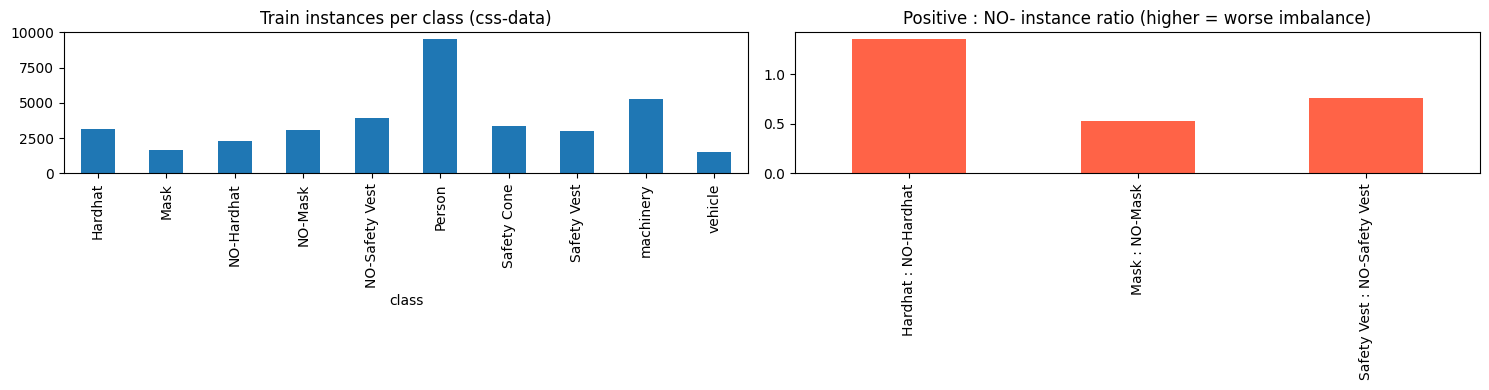

{
  "Hardhat : NO-Hardhat": 1.357358653431161,
  "Mask : NO-Mask": 0.5330965450435906,
  "Safety Vest : NO-Safety Vest": 0.7655224634023221
}

Images containing each class (train):
  Hardhat           1314 / 2605
  Mask              1096 / 2605
  NO-Hardhat        1380 / 2605
  NO-Mask           1531 / 2605
  NO-Safety Vest    1864 / 2605
  Person            2526 / 2605
  Safety Cone        631 / 2605
  Safety Vest       1319 / 2605
  machinery         2101 / 2605
  vehicle            744 / 2605


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
eda_df.set_index('class')['train_instances'].plot.bar(ax=ax[0], title='Train instances per class (css-data)')
pairs = [('Hardhat','NO-Hardhat'), ('Mask','NO-Mask'), ('Safety Vest','NO-Safety Vest')]
ratio = {f"{p} : {n}": train_counts.get(CSS_CLASSES.index(p),0) / max(1, train_counts.get(CSS_CLASSES.index(n),1))
         for p, n in pairs}
pd.Series(ratio).plot.bar(ax=ax[1], title='Positive : NO- instance ratio (higher = worse imbalance)', color='tomato')
plt.tight_layout(); plt.show()
print(json.dumps(ratio, indent=2))


img_freq = Counter()
for s in stats['train']['sets']:
    for c in s: img_freq[c] += 1
print("\nImages containing each class (train):")
for i, name in enumerate(CSS_CLASSES):
    print(f"  {name:16s} {img_freq.get(i,0):5d} / {stats['train']['n_imgs']}")

In [5]:
def audit_and_clean(base, split, nc, log):
    img_dir, lbl_dir = f"{base}/{split}/images", f"{base}/{split}/labels"
    if not os.path.isdir(img_dir): return
    imgs = {os.path.splitext(f)[0]: f for f in os.listdir(img_dir)}
    lbls = {os.path.splitext(f)[0] for f in os.listdir(lbl_dir)} if os.path.isdir(lbl_dir) else set()

    log['images_without_labels'] += len(set(imgs) - lbls)
    log['labels_without_images'] += len(lbls - set(imgs))

    for stem, fname in imgs.items():
        p = os.path.join(img_dir, fname)
        try:
            with Image.open(p) as im: im.verify()
        except Exception:
            log['corrupt_images'].append(p); continue

    for lf in glob.glob(f"{lbl_dir}/*.txt"):
        kept, dropped = [], 0
        with open(lf) as f:
            for line in f.read().strip().splitlines():
                parts = line.split()
                if len(parts) != 5: dropped += 1; continue
                try:
                    cid = int(parts[0]); x, y, w, h = map(float, parts[1:])
                except ValueError:
                    dropped += 1; continue
                if not (0 <= cid < nc): dropped += 1; continue
                if not all(0.0 <= v <= 1.0001 for v in (x, y, w, h)): dropped += 1; continue
                if w < 1e-4 or h < 1e-4: dropped += 1; continue
                kept.append(line)
        if dropped:
            log['bad_boxes_dropped'] += dropped
            
    return log

def new_log(): return {'corrupt_images': [], 'images_without_labels': 0,
                       'labels_without_images': 0, 'bad_boxes_dropped': 0}

audit_logs = {}
for name, base, nc in [('css-data', CSS_BASE, 10)]:
    log = new_log()
    for split in ['train', 'valid', 'test']:
        audit_and_clean(base, split, nc, log)
    audit_logs[name] = log

for name, base in [('ds1', BASE_DS1), ('ds2', BASE_DS2), ('ds3', BASE_DS3)]:
    with open(f"{base}/data.yaml") as f: nc = len(yaml.safe_load(f)['names'])
    log = new_log()
    for split in ['train', 'valid', 'test']:
        audit_and_clean(base, split, nc, log)
    audit_logs[name] = log

for k, v in audit_logs.items():
    print(k, {kk: (len(vv) if isinstance(vv, list) else vv) for kk, vv in v.items() if kk != '_kept_cache'})

css-data {'corrupt_images': 0, 'images_without_labels': 0, 'labels_without_images': 0, 'bad_boxes_dropped': 0}
ds1 {'corrupt_images': 0, 'images_without_labels': 0, 'labels_without_images': 0, 'bad_boxes_dropped': 0}
ds2 {'corrupt_images': 0, 'images_without_labels': 0, 'labels_without_images': 0, 'bad_boxes_dropped': 3}
ds3 {'corrupt_images': 0, 'images_without_labels': 0, 'labels_without_images': 0, 'bad_boxes_dropped': 0}


In [6]:
import imagehash

def hash_split(base, split, tag, out):
    img_dir = f"{base}/{split}/images"
    if not os.path.isdir(img_dir): return
    for fname in os.listdir(img_dir):
        p = os.path.join(img_dir, fname)
        try:
            with Image.open(p) as im:
                out[str(imagehash.phash(im))].append((tag, split, p))
        except Exception:
            pass

hashes = defaultdict(list)
for tag, base in [('css', CSS_BASE), ('ds1', BASE_DS1), ('ds2', BASE_DS2), ('ds3', BASE_DS3)]:
    for split in ['train', 'valid', 'test']:
        hash_split(base, split, tag, hashes)

dupes = {h: v for h, v in hashes.items() if len(v) > 1}
cross_test_dupes = set()
for h, v in dupes.items():
    sources = {(tag, split) for tag, split, _ in v}
    if any(t == 'css' and s == 'test' for t, s in sources) and any(s == 'train' for t, s in sources):
        for tag, split, p in v:
            if split == 'train':
                cross_test_dupes.add(p)

print(f"duplicate groups: {len(dupes)}")
print(f"train images that duplicate a css-data TEST image (will be EXCLUDED from merge): {len(cross_test_dupes)}")

css_train_test_leak = set()
css_train_valid_leak = set()
for h, v in dupes.items():
    sources = {(tag, split) for tag, split, _ in v}
    if ('css', 'train') in sources and ('css', 'test') in sources:
        css_train_test_leak.add(h)
    if ('css', 'train') in sources and ('css', 'valid') in sources:
        css_train_valid_leak.add(h)

print(f"css-data train-test duplicate groups: {len(css_train_test_leak)}")
print(f"css-data train-valid duplicate groups: {len(css_train_valid_leak)}")

ds2_test_dupes_with_train = set()
for h, v in dupes.items():
    sources = {(tag, split) for tag, split, _ in v}
    if any(t == 'ds2' and s == 'test' for t, s in sources) and any(s == 'train' for t, s in sources):
        for tag, split, p in v:
            if tag == 'ds2' and split == 'test':
                ds2_test_dupes_with_train.add(p)
print(f"ds2 test images duplicating a train image (excluded): {len(ds2_test_dupes_with_train)}")

with open(f'{WORK}/phase2_duplicates_log.json', 'w') as f:
    json.dump({
        'n_duplicate_groups': len(dupes),
        'excluded_train_dupes': sorted(cross_test_dupes),
        'css_train_test_self_leak_groups': len(css_train_test_leak),
        'css_train_valid_self_leak_groups': len(css_train_valid_leak),
        'ds2_test_dupes_excluded': len(ds2_test_dupes_with_train),
    }, f, indent=2)

duplicate groups: 16751
train images that duplicate a css-data TEST image (will be EXCLUDED from merge): 35
css-data train-test duplicate groups: 0
css-data train-valid duplicate groups: 0
ds2 test images duplicating a train image (excluded): 2214


In [7]:
MASTER = CSS_CLASSES + ['Gloves', 'NO-Gloves']
M = {name: i for i, name in enumerate(MASTER)}

def build_name_mapper(source_names, explicit=None):
    """source class id -> master class id (or None = drop). Name match first, then explicit overrides."""
    explicit = explicit or {}
    mapping = {}
    for sid, sname in enumerate(source_names):
        if sname in explicit:
            mapping[sid] = M.get(explicit[sname])
        elif sname in M:
            mapping[sid] = M[sname]
        else:
            mapping[sid] = None  # dropped
    return mapping

def load_names(base):
    with open(f"{base}/data.yaml") as f:
        return yaml.safe_load(f)['names']

names_ds1, names_ds2, names_ds3 = load_names(BASE_DS1), load_names(BASE_DS2), load_names(BASE_DS3)

map_ds1 = build_name_mapper(names_ds1, explicit={'head': 'NO-Hardhat', 'helmet': 'Hardhat', 'vest': 'Safety Vest'})
map_ds2 = build_name_mapper(names_ds2)  
map_ds3 = build_name_mapper(names_ds3, explicit={'Helmet': 'Hardhat', 'Vest': 'Safety Vest', 'Glove': 'Gloves'})

for tag, names, mp in [('DS1', names_ds1, map_ds1), ('DS2', names_ds2, map_ds2), ('DS3', names_ds3, map_ds3)]:
    print(tag)
    for sid, sname in enumerate(names):
        tgt = mp[sid]
        print(f"   {sname:20s} -> {MASTER[tgt] if tgt is not None else 'DROPPED'}")

DS1
   head                 -> NO-Hardhat
   helmet               -> Hardhat
   vest                 -> Safety Vest
DS2
   Fall-Detected        -> DROPPED
   Gloves               -> Gloves
   Goggles              -> DROPPED
   Hardhat              -> Hardhat
   Ladder               -> DROPPED
   Mask                 -> Mask
   NO-Gloves            -> NO-Gloves
   NO-Goggles           -> DROPPED
   NO-Hardhat           -> NO-Hardhat
   NO-Mask              -> NO-Mask
   NO-Safety Vest       -> NO-Safety Vest
   Person               -> Person
   Safety Cone          -> Safety Cone
   Safety Vest          -> Safety Vest
DS3
   Boots                -> DROPPED
   Ear-protection       -> DROPPED
   Glass                -> DROPPED
   Glove                -> Gloves
   Helmet               -> Hardhat
   Mask                 -> Mask
   Person               -> Person
   Vest                 -> Safety Vest


In [8]:
def merge_split(base, split_src, split_dst, prefix, class_map, nc_src, excluded=frozenset()):
    img_src, lbl_src = f"{base}/{split_src}/images", f"{base}/{split_src}/labels"
    img_dst, lbl_dst = f"{UNIFIED}/{split_dst}/images", f"{UNIFIED}/{split_dst}/labels"
    os.makedirs(img_dst, exist_ok=True); os.makedirs(lbl_dst, exist_ok=True)
    n_copied = n_skipped_empty = n_boxes = 0
    if not os.path.isdir(img_src): return 0, 0, 0
    for fname in os.listdir(img_src):
        p = os.path.join(img_src, fname)
        if p in excluded: continue
        stem, ext = os.path.splitext(fname)
        lf = os.path.join(lbl_src, stem + '.txt')
        kept = []
        if os.path.exists(lf):
            with open(lf) as f:
                for line in f.read().strip().splitlines():
                    parts = line.split()
                    if len(parts) != 5: continue
                    try:
                        cid = int(parts[0]); x, y, w, h = map(float, parts[1:])
                    except ValueError: continue
                    if not (0 <= cid < nc_src): continue
                    if not all(0 <= v <= 1.0001 for v in (x, y, w, h)): continue
                    if w < 1e-4 or h < 1e-4: continue
                    tgt = class_map[cid] if class_map else cid
                    if tgt is None: continue
                    kept.append(f"{tgt} {x:.6f} {y:.6f} {w:.6f} {h:.6f}")
        if class_map and not kept:
            n_skipped_empty += 1
            continue
        shutil.copy2(p, os.path.join(img_dst, f"{prefix}_{fname}"))
        with open(os.path.join(lbl_dst, f"{prefix}_{stem}.txt"), 'w') as f:
            f.write("\n".join(kept))
        n_copied += 1; n_boxes += len(kept)
    return n_copied, n_skipped_empty, n_boxes

shutil.rmtree(UNIFIED, ignore_errors=True)
merge_log = []
identity_map = {i: i for i in range(10)}

for s_src, s_dst in [('train','train'), ('valid','valid'), ('test','test')]:
    c, sk, b = merge_split(CSS_BASE, s_src, s_dst, 'css', identity_map, 10)
    merge_log.append(('css-data', s_src, s_dst, c, sk, b))

for tag, base, mp, names in [('ds1', BASE_DS1, map_ds1, names_ds1), ('ds2', BASE_DS2, map_ds2, names_ds2)]:
    for s_src, s_dst in [('train','train'), ('valid','valid')]:
        c, sk, b = merge_split(base, s_src, s_dst, tag, mp, len(names), excluded=cross_test_dupes)
        merge_log.append((tag, s_src, s_dst, c, sk, b))


c, sk, b = merge_split(BASE_DS2, 'test', 'test', 'ds2', map_ds2, len(names_ds2), excluded=ds2_test_dupes_with_train)
merge_log.append(('ds2', 'test', 'test', c, sk, b))

merge_df = pd.DataFrame(merge_log, columns=['source','src_split','dst_split','images_copied','skipped_no_mappable_boxes','boxes'])
print(merge_df)
print("\nTotals:", merge_df.groupby('dst_split')[['images_copied','boxes']].sum())

     source src_split dst_split  images_copied  skipped_no_mappable_boxes  \
0  css-data     train     train           2599                          6   
1  css-data     valid     valid            104                         10   
2  css-data      test      test             74                          8   
3       ds1     train     train          17221                          0   
4       ds1     valid     valid           2413                          0   
5       ds2     train     train          22337                       8398   
6       ds2     valid     valid           6447                       2367   
7       ds2      test      test           1468                        741   

    boxes  
0   36895  
1     697  
2     760  
3  148374  
4   20874  
5   66643  
6   19291  
7    5005  

Totals:            images_copied   boxes
dst_split                       
test                1542    5765
train              42157  251912
valid               8964   40862


In [9]:
data_yaml = {
    'path': UNIFIED,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': len(MASTER),
    'names': MASTER,
}
with open(f'{UNIFIED}/data.yaml', 'w') as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)
print(open(f'{UNIFIED}/data.yaml').read())

path: /kaggle/working/ppe_unified
train: train/images
val: valid/images
test: test/images
nc: 12
names:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Cone
- Safety Vest
- machinery
- vehicle
- Gloves
- NO-Gloves



In [10]:
import albumentations as A
import cv2

def count_unified_train():
    counts = Counter(); img_classes = {}
    for lf in glob.glob(f"{UNIFIED}/train/labels/*.txt"):
        cs = set()
        with open(lf) as f:
            for line in f.read().strip().splitlines():
                if line.strip():
                    cid = int(line.split()[0]); counts[cid] += 1; cs.add(cid)
        img_classes[lf] = cs
    return counts, img_classes

counts_before, img_classes = count_unified_train()
print("Unified train instance counts BEFORE augmentation:")
for i, n in enumerate(MASTER):
    print(f"  {n:16s} {counts_before.get(i,0):6d}")


median_count = np.median([counts_before.get(i, 0) for i in range(len(MASTER))])
factors = {}
for i in range(len(MASTER)):
    c = max(1, counts_before.get(i, 0))
    factors[i] = min(3.0, max(1.0, np.sqrt(median_count / c)))
print("\nOversample factors:", {MASTER[i]: round(f, 2) for i, f in factors.items() if f > 1.0})

Unified train instance counts BEFORE augmentation:
  Hardhat           76001
  Mask               3621
  NO-Hardhat       110181
  NO-Mask            4673
  NO-Safety Vest     5396
  Person            10561
  Safety Cone       13173
  Safety Vest       13853
  machinery          5247
  vehicle            1545
  Gloves             3381
  NO-Gloves          4280

Oversample factors: {'Mask': np.float64(1.21), 'NO-Mask': np.float64(1.07), 'machinery': np.float64(1.01), 'vehicle': np.float64(1.86), 'Gloves': np.float64(1.25), 'NO-Gloves': np.float64(1.12)}


In [11]:
import glob
fixed = 0
for lf in glob.glob(f"{UNIFIED}/train/labels/*_aug*.txt"):
    with open(lf) as f:
        lines = f.read().strip().splitlines()
    out = []
    for line in lines:
        parts = line.split()
        if parts:
            parts[0] = str(int(float(parts[0])))   # "4.0" -> "4"
            out.append(" ".join(parts))
    with open(lf, 'w') as f:
        f.write("\n".join(out))
    fixed += 1
print(f"repaired {fixed} augmented label files")

repaired 0 augmented label files


In [12]:
from ultralytics import YOLO

GLOVES_IDX = {M['Gloves'], M['NO-Gloves']}
GLOVES_ONLY = f'{WORK}/gloves_interim'
for split in ['train', 'valid']:
    img_dst, lbl_dst = f'{GLOVES_ONLY}/{split}/images', f'{GLOVES_ONLY}/{split}/labels'
    os.makedirs(img_dst, exist_ok=True); os.makedirs(lbl_dst, exist_ok=True)
    for fname in os.listdir(f'{UNIFIED}/{split}/images'):
        if not fname.startswith('ds2_'): continue
        stem = os.path.splitext(fname)[0]
        lf = f'{UNIFIED}/{split}/labels/{stem}.txt'
        if not os.path.exists(lf): continue
        with open(lf) as f:
            lines = [l for l in f.read().strip().splitlines() if l and int(l.split()[0]) in GLOVES_IDX]
        if not lines: continue
        shutil.copy2(f'{UNIFIED}/{split}/images/{fname}', f'{img_dst}/{fname}')
        remap = {M['Gloves']: 0, M['NO-Gloves']: 1}
        with open(f'{lbl_dst}/{stem}.txt', 'w') as f:
            for l in lines:
                parts = l.split(); parts[0] = str(remap[int(parts[0])])
                f.write(' '.join(parts) + '\n')

gloves_yaml = {'path': GLOVES_ONLY, 'train': 'train/images', 'val': 'valid/images', 'nc': 2, 'names': ['Gloves', 'NO-Gloves']}
with open(f'{GLOVES_ONLY}/data.yaml', 'w') as f:
    yaml.safe_dump(gloves_yaml, f, sort_keys=False)

gloves_model = YOLO('yolov8n.pt')
gloves_model.train(data=f'{GLOVES_ONLY}/data.yaml', epochs=15, imgsz=640, batch=16, seed=SEED,
                    project=f'{WORK}/gloves_interim_train', name='gloves_det', verbose=False)
gloves_best = YOLO(f'{WORK}/gloves_interim_train/gloves_det/weights/best.pt')

CONF_THRESH = 0.6
pseudo_count = 0
pseudo_log = []
for fname in os.listdir(f'{UNIFIED}/train/images'):
    if not (fname.startswith('css_') or fname.startswith('ds1_')): continue
    stem = os.path.splitext(fname)[0]
    lf = f'{UNIFIED}/train/labels/{stem}.txt'
    existing = set()
    if os.path.exists(lf):
        with open(lf) as f:
            existing = {int(l.split()[0]) for l in f.read().strip().splitlines() if l}
    if M['Gloves'] in existing or M['NO-Gloves'] in existing:
        continue
    img_path = f'{UNIFIED}/train/images/{fname}'
    res = gloves_best.predict(img_path, conf=CONF_THRESH, verbose=False)[0]
    if len(res.boxes) == 0: continue
    new_lines = []
    for b in res.boxes:
        cid_local = int(b.cls.item())
        cid_master = M['Gloves'] if cid_local == 0 else M['NO-Gloves']
        x, y, w, h = b.xywhn[0].tolist()
        new_lines.append(f"{cid_master} {x:.6f} {y:.6f} {w:.6f} {h:.6f}")
    with open(lf, 'a') as f:
        f.write('\n' + '\n'.join(new_lines))
    pseudo_count += len(new_lines)
    pseudo_log.append(fname)

print(f"pseudo-labeled gloves boxes added: {pseudo_count} across {len(pseudo_log)} images")
with open(f'{WORK}/phase2_pseudolabel_log.json', 'w') as f:
    json.dump({'conf_threshold': CONF_THRESH, 'images_pseudo_labeled': len(pseudo_log),
               'boxes_added': pseudo_count, 'sample_files': pseudo_log[:50]}, f, indent=2)

Ultralytics 8.4.109 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/gloves_interim/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=gloves_det, nbs=64, n

augmented copies created: 1095
             class  before   after  gain
0          Hardhat   76001   76473  1.01
1             Mask    3621    4202  1.16
2       NO-Hardhat  110181  110469  1.00
3          NO-Mask    4673    5196  1.11
4   NO-Safety Vest    5396    5904  1.09
5           Person   10561   11795  1.12
6      Safety Cone   13173   13962  1.06
7      Safety Vest   13853   14278  1.03
8        machinery    5247    5965  1.14
9          vehicle    1545    2113  1.37
10          Gloves    3381    4299  1.27
11       NO-Gloves    4280    6504  1.52


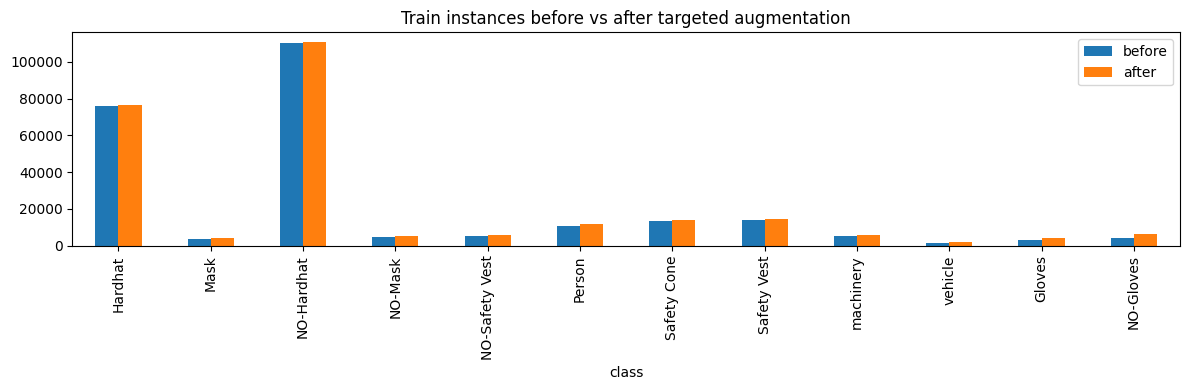

In [13]:
transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.7),
    A.HueSaturationValue(hue_shift_limit=12, sat_shift_limit=25, val_shift_limit=15, p=0.5),
    A.OneOf([A.MotionBlur(blur_limit=5), A.GaussianBlur(blur_limit=5), A.GaussNoise()], p=0.4),
    A.Affine(scale=(0.85, 1.15), rotate=(-7, 7), translate_percent=(0, 0.05), p=0.5),
], bbox_params=A.BboxParams(format='yolo', label_fields=['class_ids'], min_visibility=0.3))

def augment_image(img_path, lbl_path, out_stem, k):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    bboxes, cids = [], []
    with open(lbl_path) as f:
        for line in f.read().strip().splitlines():
            parts = line.split()
            cids.append(int(parts[0]))
            bboxes.append([min(max(float(v), 1e-6), 1 - 1e-6) for v in parts[1:]])
    made = 0
    for j in range(k):
        try:
            out = transform(image=img, bboxes=bboxes, class_ids=cids)
        except Exception:
            continue
        if not out['bboxes']: continue
        stem = f"{out_stem}_aug{j}"
        cv2.imwrite(f"{UNIFIED}/train/images/{stem}.jpg", cv2.cvtColor(out['image'], cv2.COLOR_RGB2BGR))
        with open(f"{UNIFIED}/train/labels/{stem}.txt", 'w') as f:
            for cid, bb in zip(out['class_ids'], out['bboxes']):
                f.write(f"{int(cid)} {bb[0]:.6f} {bb[1]:.6f} {bb[2]:.6f} {bb[3]:.6f}\n")
        made += 1
    return made

n_aug = 0
rng = random.Random(SEED)
items = sorted(img_classes.items())
for lf, cs in items:
    if not cs: continue
    f_img = max(factors[c] for c in cs)         
    extra = int(f_img - 1) + (1 if rng.random() < (f_img - 1) % 1 else 0)
    if extra <= 0: continue
    stem = os.path.splitext(os.path.basename(lf))[0]
    img_path = None
    for ext in ('.jpg', '.jpeg', '.png'):
        cand = f"{UNIFIED}/train/images/{stem}{ext}"
        if os.path.exists(cand): img_path = cand; break
    if img_path is None: continue
    n_aug += augment_image(img_path, lf, stem, extra)

print(f"augmented copies created: {n_aug}")
counts_after, _ = count_unified_train()
imbalance = pd.DataFrame({
    'class': MASTER,
    'before': [counts_before.get(i, 0) for i in range(len(MASTER))],
    'after': [counts_after.get(i, 0) for i in range(len(MASTER))],
})
imbalance['gain'] = (imbalance['after'] / imbalance['before'].clip(lower=1)).round(2)
print(imbalance)
imbalance.set_index('class')[['before', 'after']].plot.bar(figsize=(12, 4), title='Train instances before vs after targeted augmentation')
plt.tight_layout(); plt.show()

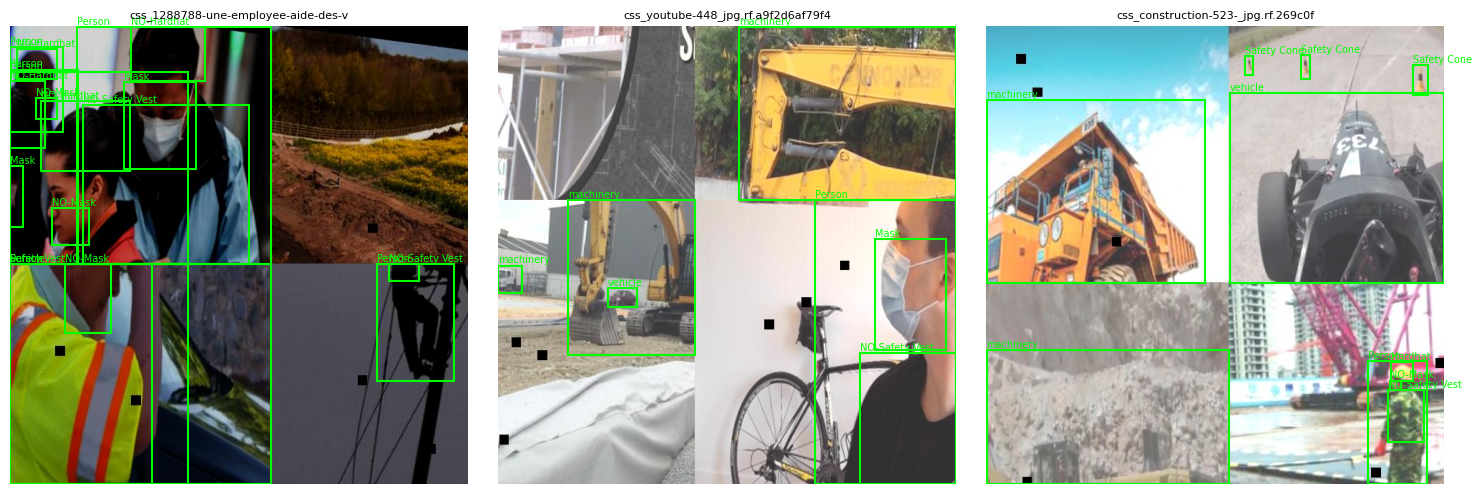

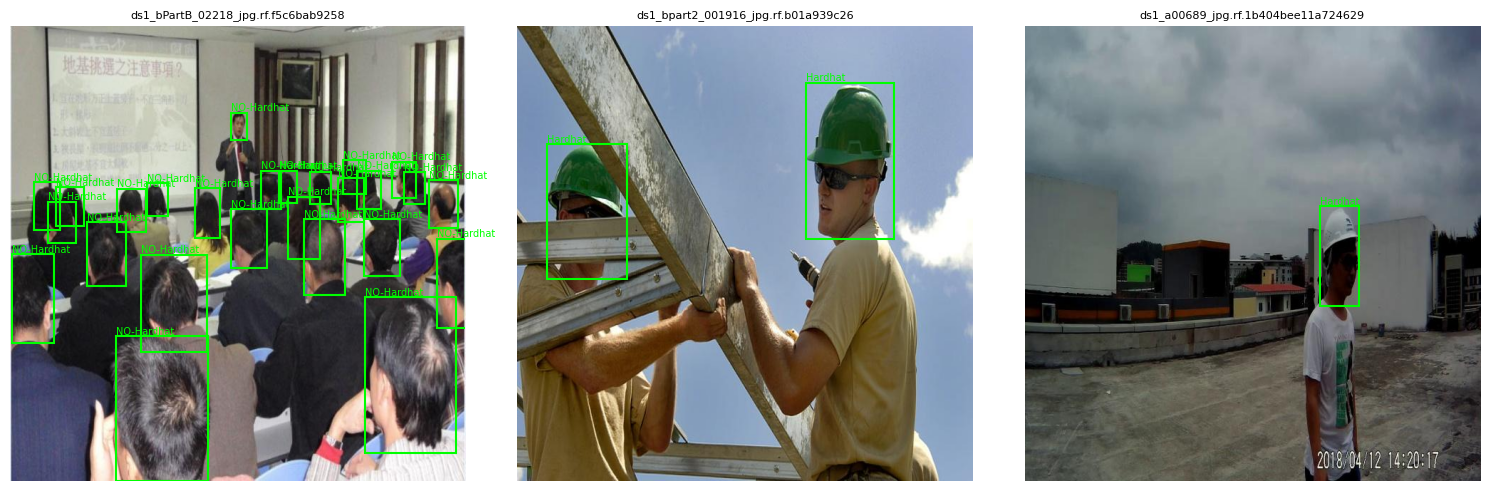

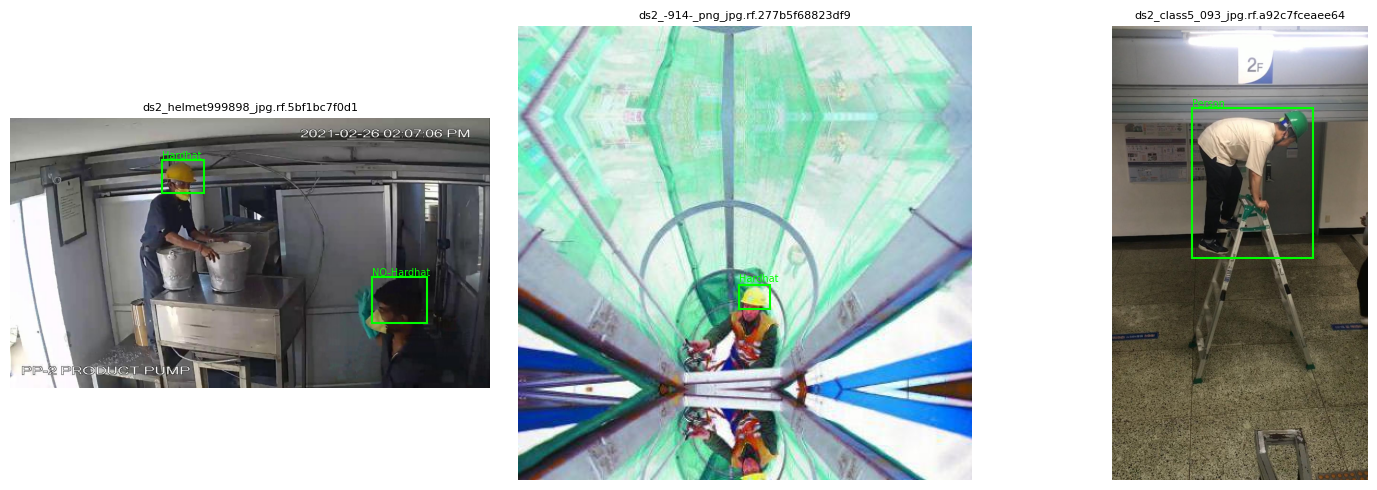

In [14]:
import matplotlib.patches as patches

def show_samples(prefix, n=3):
    files = [f for f in os.listdir(f"{UNIFIED}/train/images") if f.startswith(prefix + '_') and '_aug' not in f]
    picks = random.Random(SEED).sample(files, min(n, len(files)))
    fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 5))
    if len(picks) == 1: axes = [axes]
    for ax, fname in zip(axes, picks):
        img = Image.open(f"{UNIFIED}/train/images/{fname}"); W, H = img.size
        ax.imshow(img); ax.set_title(fname[:35], fontsize=8); ax.axis('off')
        lf = f"{UNIFIED}/train/labels/{os.path.splitext(fname)[0]}.txt"
        with open(lf) as f:
            for line in f.read().strip().splitlines():
                cid, x, y, w, h = line.split()
                cid = int(cid); x, y, w, h = map(float, (x, y, w, h))
                ax.add_patch(patches.Rectangle(((x - w/2) * W, (y - h/2) * H), w * W, h * H,
                                               fill=False, color='lime', lw=1.5))
                ax.text((x - w/2) * W, (y - h/2) * H - 3, MASTER[cid], color='lime', fontsize=7)
    plt.tight_layout(); plt.show()

for pref in ['css', 'ds1', 'ds2']:
    show_samples(pref)

In [15]:
def split_summary(split):
    n_imgs = len(os.listdir(f"{UNIFIED}/{split}/images"))
    counts = Counter()
    for lf in glob.glob(f"{UNIFIED}/{split}/labels/*.txt"):
        with open(lf) as f:
            for line in f.read().strip().splitlines():
                if line.strip(): counts[int(line.split()[0])] += 1
    return n_imgs, counts

report = {'seed': SEED, 'master_taxonomy': MASTER, 'splits': {}}
for split in ['train', 'valid', 'test']:
    n_imgs, counts = split_summary(split)
    report['splits'][split] = {
        'images': n_imgs,
        'boxes': sum(counts.values()),
        'per_class': {MASTER[i]: counts.get(i, 0) for i in range(len(MASTER))},
    }
report['augmented_copies'] = int(n_aug)
report['external_test_set'] = 'ds3_workplace_safety (untouched, evaluate in Phase 3)'
report['excluded_leaked_duplicates'] = len(cross_test_dupes)
report['css_train_test_self_leak_groups'] = len(css_train_test_leak)

with open(f'{WORK}/phase2_dataset_report.json', 'w') as f:
    json.dump(report, f, indent=2)
print(json.dumps(report, indent=2))

{
  "seed": 42,
  "master_taxonomy": [
    "Hardhat",
    "Mask",
    "NO-Hardhat",
    "NO-Mask",
    "NO-Safety Vest",
    "Person",
    "Safety Cone",
    "Safety Vest",
    "machinery",
    "vehicle",
    "Gloves",
    "NO-Gloves"
  ],
  "splits": {
    "train": {
      "images": 43252,
      "boxes": 261160,
      "per_class": {
        "Hardhat": 76473,
        "Mask": 4202,
        "NO-Hardhat": 110469,
        "NO-Mask": 5196,
        "NO-Safety Vest": 5904,
        "Person": 11795,
        "Safety Cone": 13962,
        "Safety Vest": 14278,
        "machinery": 5965,
        "vehicle": 2113,
        "Gloves": 4299,
        "NO-Gloves": 6504
      }
    },
    "valid": {
      "images": 8964,
      "boxes": 40862,
      "per_class": {
        "Hardhat": 15525,
        "Mask": 575,
        "NO-Hardhat": 15810,
        "NO-Mask": 579,
        "NO-Safety Vest": 468,
        "Person": 443,
        "Safety Cone": 3060,
        "Safety Vest": 2189,
        "machinery": 55,
        "v

In [16]:
from ultralytics import YOLO

smoke = YOLO('yolov8n.pt')
smoke_results = smoke.train(data=f'{UNIFIED}/data.yaml', epochs=2, imgsz=640, batch=16,
                            seed=SEED, project=f'{WORK}/phase2_smoke', name='smoke', verbose=False)
print("Smoke train completed — dataset is trainable.")

Ultralytics 8.4.109 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/ppe_unified/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke, nbs=64, nms=False,

In [17]:
!git clone -q https://github.com/snehilsanyal/Construction-Site-Safety-PPE-Detection.git /kaggle/working/model10_repo 2>/dev/null || true
best_phase1 = YOLO('/kaggle/working/model10_repo/models/best.pt')
ORIG_CLASSES = MASTER[:10]
BASELINE_VALID = f'{WORK}/ppe_unified_valid_baseline10'
img_dst, lbl_dst = f'{BASELINE_VALID}/images', f'{BASELINE_VALID}/labels'
os.makedirs(img_dst, exist_ok=True); os.makedirs(lbl_dst, exist_ok=True)

for fname in os.listdir(f'{UNIFIED}/valid/images'):
    stem = os.path.splitext(fname)[0]
    lf_src = f'{UNIFIED}/valid/labels/{stem}.txt'
    if not os.path.exists(lf_src): continue
    with open(lf_src) as f:
        lines = [l for l in f.read().strip().splitlines() if l and int(l.split()[0]) < 10]
    shutil.copy2(f'{UNIFIED}/valid/images/{fname}', f'{img_dst}/{fname}')
    with open(f'{lbl_dst}/{stem}.txt', 'w') as f:
        f.write('\n'.join(lines))

baseline_yaml = {'path': BASELINE_VALID, 'train': 'images', 'val': 'images', 'nc': 10, 'names': ORIG_CLASSES}
with open(f'{BASELINE_VALID}/data.yaml', 'w') as f:
    yaml.safe_dump(baseline_yaml, f, sort_keys=False)

baseline = best_phase1.val(data=f'{BASELINE_VALID}/data.yaml', split='val', plots=False)
print(f"\nPHASE 3 BASELINE TO BEAT (snehilsanyal on unified valid, original 10 classes):")
print(f"  mAP@0.5      = {baseline.box.map50:.4f}")
print(f"  mAP@0.5:0.95 = {baseline.box.map:.4f}")

with open(f'{WORK}/phase2_baseline.json', 'w') as f:
    json.dump({
        'model': 'snehilsanyal best.pt',
        'eval_set': 'ppe_unified_valid_baseline10 (Gloves excluded — old model never trained on it)',
        'mAP50': float(baseline.box.map50),
        'mAP50_95': float(baseline.box.map),
    }, f, indent=2)

Ultralytics 8.4.109 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1229.0±594.2 MB/s, size: 41.9 KB)
val: Scanning /kaggle/working/ppe_unified_valid_baseline10/labels... 8964 images, 646 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8964/8964 1.2Kit/s 7.2s
val: New cache created: /kaggle/working/ppe_unified_valid_baseline10/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 561/561 9.8it/s 57.2s
                   all       8964      38746      0.226      0.425      0.156     0.0669
               Hardhat       4997      15525       0.64      0.478      0.422      0.114
                  Mask        311        575      0.126      0.221     0.0383    0.00792
            NO-Hardhat       1610      15810     0.0955     0.0342     0.0115    0.00206
               NO-Mask        37

In [18]:
import os, shutil

CSS_ONLY_VALID = f'{WORK}/ppe_unified_css_valid'
img_src = f'{UNIFIED}/valid/images'
lbl_src = f'{UNIFIED}/valid/labels'
img_dst = f'{CSS_ONLY_VALID}/images'
lbl_dst = f'{CSS_ONLY_VALID}/labels'
os.makedirs(img_dst, exist_ok=True)
os.makedirs(lbl_dst, exist_ok=True)

n = 0
for fname in os.listdir(img_src):
    if fname.startswith('css_'):
        shutil.copy2(os.path.join(img_src, fname), os.path.join(img_dst, fname))
        stem = os.path.splitext(fname)[0]
        lf = os.path.join(lbl_src, stem + '.txt')
        if os.path.exists(lf):
            shutil.copy2(lf, os.path.join(lbl_dst, stem + '.txt'))
        n += 1

print(f"css-only valid images copied: {n}")

css-only valid images copied: 104


In [19]:
css_valid_yaml = {
    'path': CSS_ONLY_VALID,
    'train': 'images',  
    'val': 'images',
    'nc': len(MASTER),
    'names': MASTER,
}
with open(f'{CSS_ONLY_VALID}/data.yaml', 'w') as f:
    yaml.safe_dump(css_valid_yaml, f, sort_keys=False)
print(open(f'{CSS_ONLY_VALID}/data.yaml').read())

path: /kaggle/working/ppe_unified_css_valid
train: images
val: images
nc: 12
names:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Cone
- Safety Vest
- machinery
- vehicle
- Gloves
- NO-Gloves



In [20]:
baseline_css_only = best_phase1.val(data=f'{CSS_ONLY_VALID}/data.yaml', split='val', plots=False)
print(f"\nFAIR PHASE 3 BASELINE (css-data-only valid subset):")
print(f"  mAP@0.5      = {baseline_css_only.box.map50:.4f}")
print(f"  mAP@0.5:0.95 = {baseline_css_only.box.map:.4f}")

with open(f'{WORK}/phase2_baseline.json', 'w') as f:
    json.dump({
        'model': 'snehilsanyal best.pt',
        'mixed_valid_full': {'mAP50': float(baseline.box.map50), 'mAP50_95': float(baseline.box.map)},
        'css_only_valid_subset': {'mAP50': float(baseline_css_only.box.map50), 'mAP50_95': float(baseline_css_only.box.map)},
        'note': 'css_only_valid_subset is the fair Phase 3 target — mixed_valid_full is dominated by ds1/ds2 (94-99%) and not representative of the primary domain.'
    }, f, indent=2)
print("saved updated phase2_baseline.json")

Ultralytics 8.4.109 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1462.1±323.9 MB/s, size: 61.8 KB)
val: Scanning /kaggle/working/ppe_unified_css_valid/labels... 104 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 104/104 1.1Kit/s 0.1s
val: New cache created: /kaggle/working/ppe_unified_css_valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 7.3it/s 1.0s
                   all        104        697      0.916      0.727      0.801      0.499
               Hardhat         42         79      0.921      0.736      0.841      0.549
                  Mask         19         21      0.967      0.905      0.917      0.657
            NO-Hardhat         37         69      0.918      0.565      0.713      0.395
               NO-Mask         44         74       0.89      0.581      0.635       0.33
        NO-Safety Vest         56        106   

In [21]:
!cd /kaggle/working && zip -qr ppe_unified.zip ppe_unified -x "*/phase2_smoke/*"
print("Saved: /kaggle/working/ppe_unified.zip, phase2_dataset_report.json, phase2_baseline.json, phase2_duplicates_log.json")

Saved: /kaggle/working/ppe_unified.zip, phase2_dataset_report.json, phase2_baseline.json, phase2_duplicates_log.json


In [22]:
import os
print(os.path.exists('/kaggle/working/ppe_unified/data.yaml'))
print(len(os.listdir('/kaggle/working/ppe_unified/train/images')) if os.path.exists('/kaggle/working/ppe_unified/train/images') else 0)

True
43252
